# So sánh mô hình Cổ điển · Machine Learning · Foundation Model
## cho Dự báo XÁC SUẤT nhu cầu gián đoạn trong bán lẻ (M5), có phân nhóm demand

**Mục đích notebook này:** chạy thử toàn bộ *plan nghiên cứu* (P1→P5) trong **một notebook duy nhất**
để xem thực tế vận hành có khác kế hoạch không, trước khi giao cho nhóm.

Luồng: **P1** Dữ liệu → **P2** EDA & phân nhóm SBC → **P3** Contracts (quantile, NB, metrics) →
**P4** LightGBM → **P5** Cổ điển → **P6** Foundation models → **P7** Đánh giá & tổng hợp →
**P8** *Thực tế vs Plan*.

> ⚠️ **Ràng buộc môi trường đã biết:** máy **chỉ CPU** (torch CPU, không GPU) — khác giả định "Colab T4" trong plan.
> Lần chạy thử này: FM chỉ **Chronos-Bolt + TTM** (zero-shot), mẫu **pilot ~200 chuỗi/nhóm**, **1 cửa sổ test 28 ngày**.
> Mọi quy mô đều tham số hoá trong `CONFIG` để tăng sau này.

---
## §0 — Setup: cài package, cấu hình, seed

Cell dưới cố gắng `pip install` các package còn thiếu. Nếu cái nào cài/kịp import thất bại,
notebook vẫn chạy tiếp và **tự tắt** phần liên quan (cờ `AVAILABLE`). Đây chính là dữ kiện cho mục *Thực tế vs Plan*.

In [1]:
# --- 0.1 Cài các package còn thiếu (im lặng, không dừng notebook nếu lỗi) -----
import sys, subprocess, importlib, time, warnings, os, json, math, random
warnings.filterwarnings("ignore")

PKGS = [
    ("pyarrow", "pyarrow"),                 # đọc/ghi parquet
    ("lightgbm", "lightgbm"),               # ML baseline
    ("statsforecast", "statsforecast"),     # Croston/SBA/TSB/Naive/SeasonalNaive
    ("utilsforecast", "utilsforecast"),     # tiện ích (đi kèm statsforecast)
    ("chronos-forecasting", "chronos"),     # Chronos-Bolt (FM)
    ("transformers", "transformers"),       # backbone cho FM
    ("accelerate", "accelerate"),           # tiện ích load model
    ("granite-tsfm", "tsfm_public"),        # TTM (TinyTimeMixer) của IBM
]

def has_module(mod):
    try:
        importlib.import_module(mod)
        return True
    except Exception:
        return False

def pip_install(pkg):
    try:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", pkg],
            stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT, timeout=1200,
        )
        return True, ""
    except Exception as e:
        return False, str(e)[:200]

INSTALL_LOG = {}
for p, mod in PKGS:
    if has_module(mod):
        INSTALL_LOG[p] = "ok (already installed)"
        print(f"  ✓ {p}: {INSTALL_LOG[p]}")
        continue
    ok, err = pip_install(p)
    INSTALL_LOG[p] = "ok (installed)" if ok else f"FAIL: {err}"
    print(f"  {'✓' if ok else '✗'} {p}: {INSTALL_LOG[p]}")
print("\\nKiểm tra/cài đặt package xong (lỗi ở đây không làm dừng notebook).")

  ✓ pyarrow: ok (already installed)


  ✓ lightgbm: ok (already installed)


  ✓ statsforecast: ok (already installed)
  ✓ utilsforecast: ok (already installed)


  ✓ chronos-forecasting: ok (already installed)
  ✓ transformers: ok (already installed)
  ✓ accelerate: ok (already installed)


  ✓ granite-tsfm: ok (already installed)
\nKiểm tra/cài đặt package xong (lỗi ở đây không làm dừng notebook).


In [2]:
# --- 0.2 Import lõi + dò package nào dùng được ------------------------------
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
np.random.seed(42); random.seed(42)
plt.rcParams["figure.figsize"] = (9, 4); plt.rcParams["axes.grid"] = True

def can_import(mod):
    try:
        importlib.import_module(mod); return True
    except Exception:
        return False

AVAILABLE = {
    "pyarrow":      can_import("pyarrow"),
    "lightgbm":     can_import("lightgbm"),
    "statsforecast":can_import("statsforecast"),
    "chronos":      can_import("chronos"),
    "torch":        can_import("torch"),
    "ttm":          can_import("tsfm_public"),
}
try:
    import torch
    AVAILABLE["cuda"] = torch.cuda.is_available()
except Exception:
    AVAILABLE["cuda"] = False

print("Package/phần cứng dùng được:")
for k, v in AVAILABLE.items():
    print(f"  {'✓' if v else '✗'} {k}: {v}")
PARQUET_ENGINE = "pyarrow" if AVAILABLE["pyarrow"] else None

Package/phần cứng dùng được:
  ✓ pyarrow: True
  ✓ lightgbm: True
  ✓ statsforecast: True
  ✓ chronos: True
  ✓ torch: True
  ✓ ttm: True
  ✗ cuda: False


In [3]:
# --- 0.3 CONFIG: mọi hằng số & đường dẫn đông cứng ở một nơi ----------------
from pathlib import Path

CONFIG = dict(
    SEED               = 42,
    HORIZON            = 28,          # dài dự báo chuẩn M5
    SAMPLE_PER_SEGMENT = 200,         # pilot; tăng lên 1000 theo plan khi có GPU
    # --- split theo thời gian (actuals tối đa có được = d_1941 từ file evaluation) ---
    TRAIN_END   = 1885,              # train = d_1..d_1885
    VAL_END     = 1913,             # val   = d_1886..d_1913
    TEST_END    = 1941,             # test  = d_1914..d_1941  (28 ngày)
    # --- 9 mức quantile M5 ---
    QUANTILES = [0.005, 0.025, 0.165, 0.25, 0.5, 0.75, 0.835, 0.975, 0.995],
    # --- ngưỡng SBC ---
    ADI_TH = 1.32, CV2_TH = 0.49,
    # --- FM (nhẹ, chạy CPU) ---
    CHRONOS_MODEL   = "amazon/chronos-bolt-base",
    CHRONOS_CONTEXT = 512,
    TTM_MODEL       = "ibm-granite/granite-timeseries-ttm-r2",
    TTM_CONTEXT     = 512,
)
CONFIG["TEST_START"] = CONFIG["VAL_END"] + 1   # d_1914
Q = CONFIG["QUANTILES"]

RAW = Path("raw-data")
OUT = Path("outputs"); FC = OUT / "forecasts"
OUT.mkdir(exist_ok=True); FC.mkdir(parents=True, exist_ok=True)

def save_parquet(df, path):
    path = Path(path)
    if PARQUET_ENGINE:
        df.to_parquet(path, index=False)
    else:  # fallback CSV nếu không có pyarrow
        path = path.with_suffix(".csv"); df.to_csv(path, index=False)
    return path

print("CONFIG:")
for k, v in CONFIG.items():
    print(f"  {k}: {v}")

CONFIG:
  SEED: 42
  HORIZON: 28
  SAMPLE_PER_SEGMENT: 200
  TRAIN_END: 1885
  VAL_END: 1913
  TEST_END: 1941
  QUANTILES: [0.005, 0.025, 0.165, 0.25, 0.5, 0.75, 0.835, 0.975, 0.995]
  ADI_TH: 1.32
  CV2_TH: 0.49
  CHRONOS_MODEL: amazon/chronos-bolt-base
  CHRONOS_CONTEXT: 512
  TTM_MODEL: ibm-granite/granite-timeseries-ttm-r2
  TTM_CONTEXT: 512
  TEST_START: 1914


---
## §1 (P1) — Dữ liệu & hạ tầng

Đọc M5 từ `raw-data/`. Dùng **`sales_train_evaluation.csv`** vì nó chứa tới `d_1941`
(đủ actuals cho cả val và test). Tính **ADI/CV²** trực tiếp trên ma trận *wide* (chỉ phần train,
`d_1..d_1885`) — vectorised, không melt toàn bộ 30.490 chuỗi để tiết kiệm bộ nhớ.

In [4]:
# --- 1.1 Đọc dữ liệu thô -----------------------------------------------------
t0 = time.time()
calendar = pd.read_csv(RAW / "calendar.csv")
prices   = pd.read_csv(RAW / "sell_prices.csv")
sales    = pd.read_csv(RAW / "sales_train_evaluation.csv")   # d_1..d_1941

ID_COLS  = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
D_COLS   = [c for c in sales.columns if c.startswith("d_")]
N_DAYS   = len(D_COLS)
print(f"sales: {sales.shape} | ngày lịch sử: {N_DAYS} (d_1..d_{N_DAYS})")
print(f"calendar: {calendar.shape} | prices: {prices.shape}")
print(f"Số chuỗi (item×store): {sales['id'].nunique():,}")
print(f"Đọc xong trong {time.time()-t0:.1f}s")
sales.head(3)

sales: (30490, 1947) | ngày lịch sử: 1941 (d_1..d_1941)
calendar: (1969, 14) | prices: (6841121, 4)
Số chuỗi (item×store): 30,490
Đọc xong trong 4.4s


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,4,0,0,0,0,3,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,1,2,1,1,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,2,0,0,0,2,3,0,1


In [5]:
# --- 1.2 schema: khai báo cột & ngày split (thay cho src/common/schema.py) ---
schema = dict(
    id_cols   = ID_COLS,
    target    = "sales",
    time_key  = "d",
    date_col  = "date",
    train_days = [f"d_{i}" for i in range(1, CONFIG['TRAIN_END']+1)],
    val_days   = [f"d_{i}" for i in range(CONFIG['TRAIN_END']+1, CONFIG['VAL_END']+1)],
    test_days  = [f"d_{i}" for i in range(CONFIG['VAL_END']+1, CONFIG['TEST_END']+1)],
)
print("train:", schema['train_days'][0], "->", schema['train_days'][-1],
      "| val:", schema['val_days'][0], "->", schema['val_days'][-1],
      "| test:", schema['test_days'][0], "->", schema['test_days'][-1])
assert len(schema['test_days']) == CONFIG['HORIZON']

train: d_1 -> d_1885 | val: d_1886 -> d_1913 | test: d_1914 -> d_1941


In [6]:
# --- 1.3 ADI & CV^2 trên ma trận wide (chỉ dùng train để tránh rò rỉ) --------
train_mat = sales[schema['train_days']].to_numpy(dtype=np.float32)   # (n_series, n_train_days)
T = train_mat.shape[1]

nonzero_mask   = train_mat > 0
n_nonzero      = nonzero_mask.sum(axis=1)                            # số kỳ có nhu cầu
sum_nz         = np.where(nonzero_mask, train_mat, 0).sum(axis=1)
mean_nz        = np.divide(sum_nz, n_nonzero, out=np.zeros_like(sum_nz), where=n_nonzero>0)
# std của các giá trị khác 0
sq = np.where(nonzero_mask, train_mat**2, 0).sum(axis=1)
var_nz = np.divide(sq, n_nonzero, out=np.zeros_like(sq), where=n_nonzero>0) - mean_nz**2
var_nz = np.clip(var_nz, 0, None)
std_nz = np.sqrt(var_nz)

with np.errstate(divide="ignore", invalid="ignore"):
    ADI = np.where(n_nonzero > 0, T / n_nonzero, np.inf)
    CV2 = np.where(mean_nz > 0, (std_nz / mean_nz) ** 2, 0.0)

seg_df = sales[ID_COLS].copy()
seg_df["series_id"] = seg_df["id"]
seg_df["n_nonzero"] = n_nonzero
seg_df["zero_rate"] = 1 - n_nonzero / T
seg_df["ADI"] = ADI
seg_df["CV2"] = CV2
print("Tính ADI/CV^2 xong.")
seg_df[["series_id","zero_rate","ADI","CV2"]].describe()

Tính ADI/CV^2 xong.


,zero_rate,ADI,CV2
count,30490.000000,30490.000000,30490.000000
mean,0.683733,6.810004,0.389168
std,0.224163,14.927610,0.693379
min,0.001592,1.001594,0.000000
25%,0.538992,2.169160,0.228304
50%,0.737931,3.815789,0.347386
75%,0.868966,7.631579,0.461846
max,0.999469,1885.000000,106.577362


---
## §2 (P2) — EDA & phân nhóm demand (SBC)

Áp ngưỡng **SBC** (`ADI=1.32`, `CV²=0.49`) → 4 nhóm *smooth / erratic / intermittent / lumpy*.
Lấy **mẫu phân tầng** `min(có sẵn, SAMPLE_PER_SEGMENT)` chuỗi/nhóm (seed cố định) — danh sách này
dùng chung cho MỌI mô hình để so sánh công bằng theo nhóm.

In [7]:
# --- 2.1 Áp ngưỡng SBC -> nhãn nhóm -----------------------------------------
adi_th, cv2_th = CONFIG["ADI_TH"], CONFIG["CV2_TH"]
cond = [
    (seg_df.ADI <  adi_th) & (seg_df.CV2 <  cv2_th),   # smooth
    (seg_df.ADI <  adi_th) & (seg_df.CV2 >= cv2_th),   # erratic
    (seg_df.ADI >= adi_th) & (seg_df.CV2 <  cv2_th),   # intermittent
    (seg_df.ADI >= adi_th) & (seg_df.CV2 >= cv2_th),   # lumpy
]
seg_df["segment"] = np.select(cond, ["smooth","erratic","intermittent","lumpy"], default="intermittent")

summary = (seg_df.groupby("segment")
           .agg(n_series=("series_id","size"),
                zero_rate=("zero_rate","mean"),
                ADI=("ADI", lambda s: np.median(s[np.isfinite(s)])),
                CV2=("CV2","median"))
           .reindex(["smooth","erratic","intermittent","lumpy"]))
summary["pct"] = (summary.n_series / summary.n_series.sum() * 100).round(1)
print("Phân bố nhóm demand (toàn bộ 30.490 chuỗi):")
print(summary.round(3))

Phân bố nhóm demand (toàn bộ 30.490 chuỗi):
              n_series  zero_rate    ADI    CV2   pct
segment                                              
smooth             980      0.138  1.177  0.374   3.2
erratic            494      0.167  1.216  0.614   1.6
intermittent     23096      0.738  4.598  0.298  75.7
lumpy             5920      0.604  2.503  0.619  19.4


In [8]:
# --- 2.2 Mẫu phân tầng + lưu artifacts --------------------------------------
rng = np.random.RandomState(CONFIG["SEED"])
picks = []
for seg, g in seg_df.groupby("segment"):
    n = min(len(g), CONFIG["SAMPLE_PER_SEGMENT"])
    picks.append(g.sample(n=n, random_state=CONFIG["SEED"]))
sample_df = pd.concat(picks).reset_index(drop=True)
sample_ids = sample_df["series_id"].tolist()
print(f"Số chuỗi mẫu: {len(sample_ids)}  ({sample_df.segment.value_counts().to_dict()})")

# segment_labels + sample_ids (dùng chung)
seg_labels = seg_df[["series_id","ADI","CV2","zero_rate","segment"]].copy()
save_parquet(seg_labels, OUT / "segment_labels.parquet")
pd.DataFrame({"series_id": sample_ids}).to_csv(OUT / "sample_ids.csv", index=False)
print("Đã lưu segment_labels + sample_ids.")

Số chuỗi mẫu: 800  ({'erratic': 200, 'intermittent': 200, 'lumpy': 200, 'smooth': 200})
Đã lưu segment_labels + sample_ids.


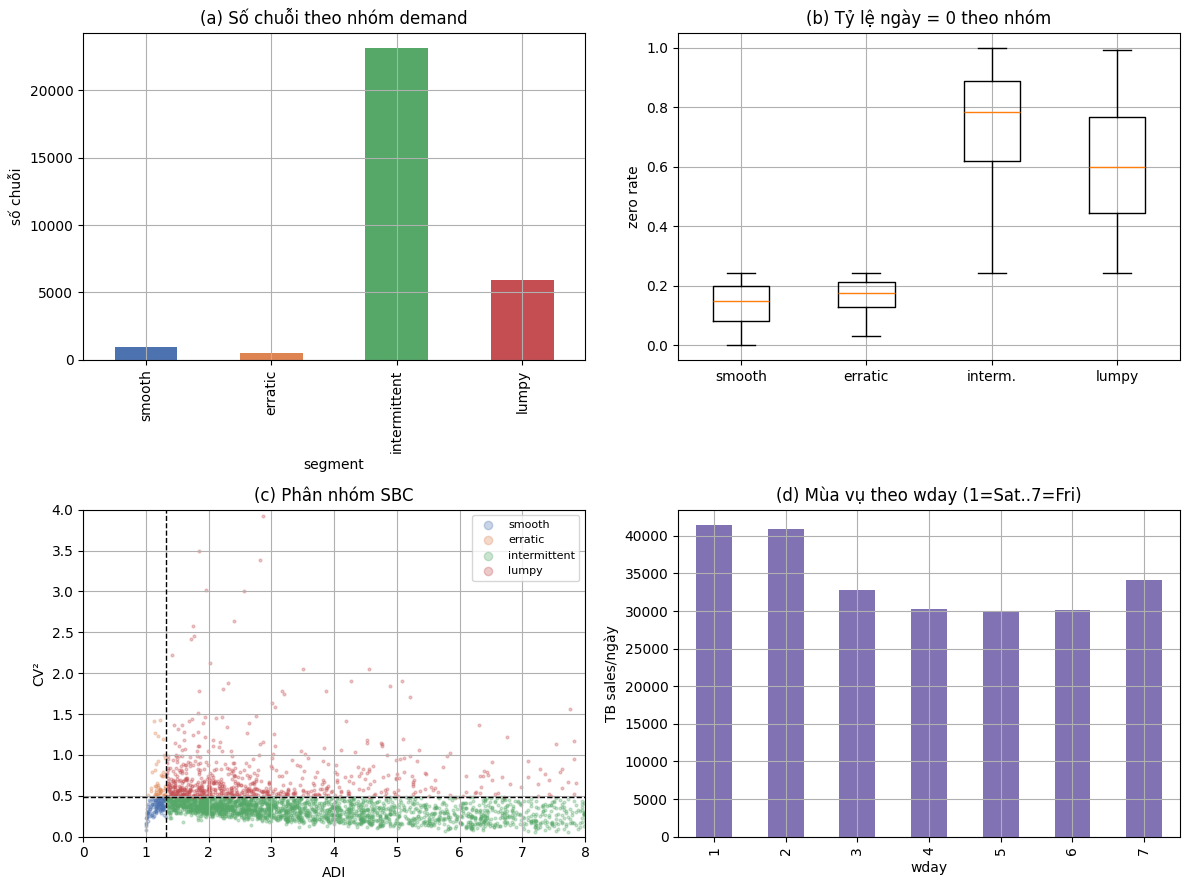

In [9]:
# --- 2.3 EDA trực quan -------------------------------------------------------
fig, ax = plt.subplots(2, 2, figsize=(12, 9))

# (a) số chuỗi theo nhóm
summary.n_series.plot.bar(ax=ax[0,0], color=["#4c72b0","#dd8452","#55a868","#c44e52"])
ax[0,0].set_title("(a) Số chuỗi theo nhóm demand"); ax[0,0].set_ylabel("số chuỗi")

# (b) tỷ lệ zero theo nhóm
data = [seg_df.loc[seg_df.segment==s, "zero_rate"].values
        for s in ["smooth","erratic","intermittent","lumpy"]]
ax[0,1].boxplot(data, labels=["smooth","erratic","interm.","lumpy"], showfliers=False)
ax[0,1].set_title("(b) Tỷ lệ ngày = 0 theo nhóm"); ax[0,1].set_ylabel("zero rate")

# (c) scatter ADI vs CV^2 (mẫu để nhẹ) + ngưỡng
s = seg_df[np.isfinite(seg_df.ADI)].sample(min(4000, len(seg_df)), random_state=1)
colors = {"smooth":"#4c72b0","erratic":"#dd8452","intermittent":"#55a868","lumpy":"#c44e52"}
for seg in colors:
    d = s[s.segment==seg]
    ax[1,0].scatter(d.ADI, d.CV2, s=4, alpha=0.3, label=seg, color=colors[seg])
ax[1,0].axvline(adi_th, ls="--", c="k", lw=1); ax[1,0].axhline(cv2_th, ls="--", c="k", lw=1)
ax[1,0].set_xlim(0, 8); ax[1,0].set_ylim(0, 4)
ax[1,0].set_xlabel("ADI"); ax[1,0].set_ylabel("CV²"); ax[1,0].set_title("(c) Phân nhóm SBC")
ax[1,0].legend(markerscale=3, fontsize=8)

# (d) mùa vụ theo thứ trong tuần (tổng sales toàn tập, dùng calendar)
wd = calendar[["d","wday"]].merge(
        sales[schema['train_days']].sum(axis=0).rename("tot").reset_index().rename(columns={"index":"d"}),
        on="d")
wd.groupby("wday").tot.mean().plot.bar(ax=ax[1,1], color="#8172b3")
ax[1,1].set_title("(d) Mùa vụ theo wday (1=Sat..7=Fri)"); ax[1,1].set_ylabel("TB sales/ngày")

plt.tight_layout(); plt.show()

In [10]:
# --- 2.4 Melt CHỈ các chuỗi mẫu sang long + join calendar/prices ------------
t0 = time.time()
cal_keep = ["d","date","wm_yr_wk","wday","month","year",
            "event_name_1","event_type_1","snap_CA","snap_TX","snap_WI"]
sub = sales[sales["id"].isin(sample_ids)].copy()
long = sub.melt(id_vars=ID_COLS, value_vars=D_COLS, var_name="d", value_name="sales")
long = long.merge(calendar[cal_keep], on="d", how="left")
long = long.merge(prices, on=["store_id","item_id","wm_yr_wk"], how="left")

long["series_id"] = long["id"]
long["date"] = pd.to_datetime(long["date"])
long["d_int"] = long["d"].str.slice(2).astype("int32")
long["is_event"] = long["event_name_1"].notna().astype("int8")
# SNAP theo bang của chuỗi
snap_map = {"CA":"snap_CA","TX":"snap_TX","WI":"snap_WI"}
long["snap"] = 0
for st, col in snap_map.items():
    m = long.state_id == st
    long.loc[m, "snap"] = long.loc[m, col].values
long["snap"] = long["snap"].astype("int8")

# downcast
for c in ["sales"]:
    long[c] = long[c].astype("float32")
long = long.merge(seg_labels[["series_id","segment"]], on="series_id", how="left")
long = long.sort_values(["series_id","d_int"]).reset_index(drop=True)
print(f"data_long: {long.shape}  |  {time.time()-t0:.1f}s")
print(f"Bộ nhớ ~ {long.memory_usage(deep=True).sum()/1e6:.0f} MB")
long.head(3)

data_long: (1552800, 24)  |  4.7s


Bộ nhớ ~ 1190 MB


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,event_type_1,snap_CA,snap_TX,snap_WI,sell_price,series_id,d_int,is_event,snap,segment
0,FOODS_1_006_CA_2_evaluation,FOODS_1_006,FOODS_1,FOODS,CA_2,CA,d_1,1.0,2011-01-29,11101,...,NaN,0,0,0,1.97,FOODS_1_006_CA_2_evaluation,1,0,0,lumpy
1,FOODS_1_006_CA_2_evaluation,FOODS_1_006,FOODS_1,FOODS,CA_2,CA,d_2,1.0,2011-01-30,11101,...,NaN,0,0,0,1.97,FOODS_1_006_CA_2_evaluation,2,0,0,lumpy
2,FOODS_1_006_CA_2_evaluation,FOODS_1_006,FOODS_1,FOODS,CA_2,CA,d_3,1.0,2011-01-31,11101,...,NaN,0,0,0,1.97,FOODS_1_006_CA_2_evaluation,3,0,0,lumpy


In [11]:
# --- 2.5 Bảng actuals cho test (dùng cho đánh giá) --------------------------
# actual test: các ngày d_TEST_START..d_TEST_END của chuỗi mẫu
test_days = schema["test_days"]
actual_test = (long[long.d.isin(test_days)]
               [["series_id","date","d_int","sales","segment"]]
               .rename(columns={"sales":"actual"})
               .reset_index(drop=True))
# train history (long) để tính scale RMSSE/pinball
train_hist = long[long.d_int <= CONFIG["VAL_END"]][["series_id","d_int","sales"]].copy()
print("actual_test:", actual_test.shape, "| train_hist:", train_hist.shape)

actual_test: (22400, 5) | train_hist: (1530400, 3)


---
## §3 — Giao thức chung: quantile · Negative Binomial · Metrics (thay cho `src/common/`)

**Frozen joint #2 — format forecast:** `series_id, date, d_int, quantile_level, value` (long).

**Frozen joint #3 — bung point → 9 quantile (mô hình điểm):** giả định **Negative Binomial** với
dispersion `r` cố định theo chuỗi (ước lượng từ insample: `r = m²/(v−m)` nếu `v>m`, ngược lại → Poisson),
mean = point forecast của từng bước. `value = NB.ppf(level)`.

**Metrics:** `RMSSE` (điểm, dùng P50) · `WSPL/SPL` (pinball scaled trên 9 quantile) · `coverage` (hiệu chuẩn).

In [12]:
# --- 3.1 Tiện ích scale (RMSSE & pinball) + trọng số theo chuỗi -------------
def _scales(y):
    '''scale MSE & MAE cua naive-1 tren insample, tinh tu lan ban dau tien (kieu M5).'''
    nz = np.nonzero(y)[0]
    if len(nz) < 2:
        return np.nan, np.nan
    y = y[nz[0]:]
    d = np.diff(y)
    if len(d) == 0:
        return np.nan, np.nan
    return float(np.mean(d**2)), float(np.mean(np.abs(d)))

scale_rmsse, scale_mae = {}, {}
for sid, g in train_hist.sort_values("d_int").groupby("series_id"):
    s2, s1 = _scales(g["sales"].to_numpy(dtype=np.float64))
    scale_rmsse[sid], scale_mae[sid] = s2, s1

# trọng số WSPL = doanh số 28 ngày insample cuối (kiểu M5 uncertainty)
last28 = long[(long.d_int > CONFIG["VAL_END"]-28) & (long.d_int <= CONFIG["VAL_END"])].copy()
last28["dollar"] = last28["sales"] * last28["sell_price"].fillna(0)
weight = last28.groupby("series_id")["dollar"].sum()
weight = (weight / weight.sum()).to_dict()   # chuẩn hoá tổng = 1
print(f"Đã tính scale cho {len(scale_rmsse)} chuỗi. Ví dụ scale_mae: "
      f"{list(scale_mae.items())[0]}")

Đã tính scale cho 800 chuỗi. Ví dụ scale_mae: ('FOODS_1_006_CA_2_evaluation', 1.5460251046025104)


In [13]:
# --- 3.2 Dispersion NB theo chuỗi (từ insample) -----------------------------
mv = train_hist.groupby("series_id")["sales"].agg(["mean","var"])
def _r(row):
    m, v = row["mean"], row["var"]
    if v > m and m > 0:
        return m*m / (v - m)      # r hữu hạn -> NB
    return np.inf                 # -> Poisson
disp_r = mv.apply(_r, axis=1).to_dict()

def point_to_quantiles(point_df, name):
    '''point_df: series_id,date,d_int,value(mean) -> long 9 quantile theo NB/Poisson.'''
    out = []
    pf = point_df.copy()
    pf["value"] = pf["value"].clip(lower=0).astype(float)
    pf["r"] = pf["series_id"].map(disp_r).fillna(np.inf)
    mu = pf["value"].to_numpy()
    r  = pf["r"].to_numpy()
    finite = np.isfinite(r) & (r > 0)
    for u in Q:
        qv = np.empty_like(mu)
        # NB: mean=mu, size=r  -> p = r/(r+mu)
        if finite.any():
            rr = r[finite]; mm = mu[finite]
            p = rr / (rr + np.where(mm > 0, mm, 1e-9))
            qv[finite] = stats.nbinom.ppf(u, rr, p)
        if (~finite).any():
            qv[~finite] = stats.poisson.ppf(u, mu[~finite])
        block = pf[["series_id","date","d_int"]].copy()
        block["quantile_level"] = u
        block["value"] = np.nan_to_num(qv, nan=0.0)
        out.append(block)
    res = pd.concat(out, ignore_index=True)
    res["model"] = name
    return res[["series_id","date","d_int","quantile_level","value","model"]]
print("Sẵn sàng point_to_quantiles(). Ví dụ disp_r:", list(disp_r.items())[0])

Sẵn sàng point_to_quantiles(). Ví dụ disp_r: ('FOODS_1_006_CA_2_evaluation', 0.8809118270874023)


In [14]:
# --- 3.3 evaluate(): RMSSE, SPL/WSPL, coverage theo từng chuỗi --------------
COV_PAIRS = [(0.25,0.75,0.50),(0.165,0.835,0.67),(0.025,0.975,0.95),(0.005,0.995,0.99)]

def evaluate(fdf, name):
    '''fdf: long forecast (series_id,d_int,quantile_level,value). Tra per-series metrics.'''
    piv = (fdf.pivot_table(index=["series_id","d_int"], columns="quantile_level", values="value")
              .reset_index())
    m = piv.merge(actual_test[["series_id","d_int","actual","segment"]],
                  on=["series_id","d_int"], how="inner")
    rows = []
    for sid, g in m.groupby("series_id"):
        a = g["actual"].to_numpy(dtype=float)
        p50 = g[0.5].to_numpy(dtype=float) if 0.5 in g else np.full_like(a, np.nan)
        sr, sm = scale_rmsse.get(sid, np.nan), scale_mae.get(sid, np.nan)
        rmsse = np.sqrt(np.mean((a-p50)**2)/sr) if (sr and sr > 0) else np.nan
        spls = []
        for u in Q:
            if u in g:
                q = g[u].to_numpy(dtype=float)
                pin = np.mean(np.maximum(u*(a-q), (u-1)*(a-q)))
                spls.append(pin/sm if (sm and sm > 0) else np.nan)
        spl = np.nanmean(spls) if spls else np.nan
        covs = {}
        for lo, hi, nom in COV_PAIRS:
            if lo in g and hi in g:
                inside = ((a >= g[lo].to_numpy()) & (a <= g[hi].to_numpy())).mean()
                covs[f"cov{int(nom*100)}"] = inside
        rows.append(dict(series_id=sid, segment=g["segment"].iloc[0], model=name,
                         RMSSE=rmsse, SPL=spl, weight=weight.get(sid, np.nan), **covs))
    return pd.DataFrame(rows)
print("evaluate() sẵn sàng.")

evaluate() sẵn sàng.


---
## §4 (P3) — Machine Learning: LightGBM global, 9 quantile

Feature **leak-free cho cả 28 ngày test**: chỉ dùng **lag ≥ HORIZON (28,35,56)** và rolling kết thúc ở
lag-28, nên mọi feature của d_1914..d_1941 đều tính được từ dữ liệu ≤ d_1913 (không cần recursive).
Sinh 9 quantile bằng **9 model** `objective='quantile', alpha=level`; ép **không giao nhau** (sort theo quantile).

In [15]:
# --- 4.1 Feature engineering (leak-free, lag >= 28) -------------------------
FEATS_READY = False
if AVAILABLE["lightgbm"]:
    import lightgbm as lgb
    fe = long[["series_id","d_int","date","sales","wday","month",
               "is_event","snap","sell_price","segment"]].copy()
    fe = fe.sort_values(["series_id","d_int"]).reset_index(drop=True)
    g = fe.groupby("series_id")["sales"]
    for L in (28, 35, 56):
        fe[f"lag_{L}"] = g.shift(L)
    fe["s28"] = g.shift(28)
    grp = fe.groupby("series_id")["s28"]
    fe["rmean_7"]  = grp.transform(lambda x: x.rolling(7,  min_periods=2).mean())
    fe["rmean_28"] = grp.transform(lambda x: x.rolling(28, min_periods=5).mean())
    fe["rstd_28"]  = grp.transform(lambda x: x.rolling(28, min_periods=5).std())

    # days-since-last-sale (tính tại t, rồi shift 28 để leak-free)
    def _dsls(v):
        out = np.empty(len(v)); last = -10000
        for i, x in enumerate(v):
            out[i] = i - last
            if x > 0: last = i
        return out
    fe["dsls"] = fe.groupby("series_id")["sales"].transform(lambda s: _dsls(s.to_numpy()))
    fe["dsls_28"] = fe.groupby("series_id")["dsls"].shift(28)

    # giá & thay đổi giá (giá tương lai đã biết trong M5)
    fe["price_chg"] = fe.groupby("series_id")["sell_price"].pct_change().replace([np.inf,-np.inf], 0)
    fe["sell_price"] = fe["sell_price"].fillna(fe["sell_price"].median())

    FEAT_COLS = ["lag_28","lag_35","lag_56","rmean_7","rmean_28","rstd_28",
                 "dsls_28","wday","month","is_event","snap","sell_price","price_chg"]
    CAT_COLS = ["wday","month"]
    FEATS_READY = True
    print("Feature xong:", fe.shape, "| #features:", len(FEAT_COLS))
else:
    print("⚠ Bỏ LightGBM (chưa cài được lightgbm) — sẽ ghi lại ở mục Thực tế vs Plan.")

Feature xong: (1552800, 20) | #features: 13


In [16]:
# --- 4.2 Train 9 model quantile + dự báo test ------------------------------
lgbm_fc = None
if FEATS_READY:
    t0 = time.time()
    train_mask = (fe.d_int <= CONFIG["VAL_END"]) & fe["lag_56"].notna()
    test_mask  = fe.d_int.between(CONFIG["TEST_START"], CONFIG["TEST_END"])
    Xtr = fe.loc[train_mask, FEAT_COLS]; ytr = fe.loc[train_mask, "sales"]
    Xte = fe.loc[test_mask, FEAT_COLS]
    base = fe.loc[test_mask, ["series_id","date","d_int"]].reset_index(drop=True)
    print(f"train rows: {len(Xtr):,} | test rows: {len(Xte):,}")

    params = dict(objective="quantile", learning_rate=0.05, num_leaves=63,
                  min_data_in_leaf=100, feature_fraction=0.8, bagging_fraction=0.8,
                  bagging_freq=1, verbosity=-1, num_threads=0)
    dtrain = lgb.Dataset(Xtr, label=ytr, categorical_feature=CAT_COLS, free_raw_data=False)

    preds = {}
    fi = None
    for u in Q:
        m = lgb.train({**params, "alpha": u}, dtrain, num_boost_round=200)
        preds[u] = np.clip(m.predict(Xte), 0, None)
        if abs(u-0.5) < 1e-9:
            fi = pd.Series(m.feature_importance("gain"), index=FEAT_COLS).sort_values(ascending=False)
    # ép không giao nhau giữa các quantile
    P = np.sort(np.vstack([preds[u] for u in Q]), axis=0)   # (9, n) tăng dần
    parts = []
    for i, u in enumerate(Q):
        b = base.copy(); b["quantile_level"] = u; b["value"] = P[i]; parts.append(b)
    lgbm_fc = pd.concat(parts, ignore_index=True); lgbm_fc["model"] = "lgbm"
    save_parquet(lgbm_fc, FC / "lgbm.parquet")
    print(f"LightGBM xong trong {time.time()-t0:.1f}s | forecast rows: {len(lgbm_fc):,}")
    print("\\nTop feature importance (gain, model P50):"); print(fi.head(10))

train rows: 1,485,600 | test rows: 22,400


LightGBM xong trong 66.7s | forecast rows: 201,600
\nTop feature importance (gain, model P50):
rmean_28      6.016233e+06
rstd_28       1.021086e+06
rmean_7       5.215953e+05
price_chg     4.931084e+05
dsls_28       1.768930e+05
sell_price    1.663295e+05
month         4.536182e+04
lag_28        3.262908e+04
wday          3.180520e+04
lag_56        2.035494e+04
dtype: float64


---
## §5 (P4a) — Mô hình cổ điển cho nhu cầu gián đoạn

Naive & SeasonalNaive(7) tự cài (luôn có, làm mốc). Croston / SBA / TSB dùng **statsforecast** (Nixtla).
Mọi point forecast → 9 quantile bằng **spec NB (§3)**.

In [17]:
# --- 5.1 Naive & SeasonalNaive tự cài (điểm) -> NB quantile -----------------
DINT = dict(zip(pd.to_datetime(calendar["date"]),
                calendar["d"].str.slice(2).astype(int)))
test_dates = [d for d, i in sorted(DINT.items(), key=lambda kv: kv[1])
              if CONFIG["TEST_START"] <= i <= CONFIG["TEST_END"]]
H = CONFIG["HORIZON"]

insample = long[long.d_int <= CONFIG["VAL_END"]].sort_values(["series_id","d_int"])
classical_points = {}

# Naive: lặp giá trị cuối
last_val = insample.groupby("series_id")["sales"].last()
# SeasonalNaive: 7 giá trị cuối lặp lại
def _snaive(s):
    v = s.to_numpy()[-7:]
    if len(v) < 7: v = np.pad(v, (7-len(v),0))
    return np.tile(v, int(np.ceil(H/7)))[:H]
snaive_map = insample.groupby("series_id")["sales"].apply(_snaive)

def _expand(vals_map, name, per_series_horizon=False):
    rows = []
    for sid in sample_ids:
        if per_series_horizon:
            vals = vals_map[sid]
        else:
            vals = np.full(H, float(vals_map.get(sid, 0.0)))
        for k, (dt, v) in enumerate(zip(test_dates, vals)):
            rows.append((sid, dt, DINT[dt], float(v)))
    df = pd.DataFrame(rows, columns=["series_id","date","d_int","value"])
    return df

classical_points["naive"]  = _expand(last_val.to_dict(), "naive")
classical_points["snaive"] = _expand(snaive_map.to_dict(), "snaive", per_series_horizon=True)
print("Naive & SeasonalNaive xong.")

Naive & SeasonalNaive xong.


In [18]:
# --- 5.2 Croston / SBA / TSB qua statsforecast ------------------------------
sf_runtime = {}
if AVAILABLE["statsforecast"]:
    t0 = time.time()
    from statsforecast import StatsForecast
    from statsforecast.models import CrostonClassic, CrostonSBA, TSB
    sf_train = (insample[["series_id","date","sales"]]
                .rename(columns={"series_id":"unique_id","date":"ds","sales":"y"}))
    models = [CrostonClassic(), CrostonSBA(), TSB(alpha_d=0.2, alpha_p=0.2)]
    sf = StatsForecast(models=models, freq="D", n_jobs=1)
    fcst = sf.forecast(h=H, df=sf_train)
    colmap = {"CrostonClassic":"croston", "CrostonSBA":"sba", "TSB":"tsb"}
    for col, nm in colmap.items():
        if col in fcst.columns:
            pdf = (fcst[["unique_id","ds",col]]
                   .rename(columns={"unique_id":"series_id","ds":"date",col:"value"}))
            pdf["date"] = pd.to_datetime(pdf["date"])
            pdf["d_int"] = pdf["date"].map(DINT)
            classical_points[nm] = pdf[["series_id","date","d_int","value"]]
    sf_runtime["statsforecast(3 models)"] = round(time.time()-t0, 1)
    print(f"Croston/SBA/TSB xong trong {sf_runtime['statsforecast(3 models)']}s")
else:
    print("⚠ Bỏ Croston/SBA/TSB (chưa cài statsforecast).")

Croston/SBA/TSB xong trong 1.5s


In [19]:
# --- 5.3 Bung point -> 9 quantile (NB) & lưu -------------------------------
classical_fc = {}
for nm, pdf in classical_points.items():
    q = point_to_quantiles(pdf.dropna(subset=["d_int"]), nm)
    classical_fc[nm] = q
    save_parquet(q, FC / f"{nm}.parquet")
print("Đã lưu forecast cổ điển:", list(classical_fc.keys()))

Đã lưu forecast cổ điển: ['naive', 'snaive', 'croston', 'sba', 'tsb']


---
## §6 (P4b) — Foundation models (zero-shot, CPU)

**Chronos-Bolt (base)** cho quantile trực tiếp → nội suy về 9 mức M5.
**TTM (TinyTimeMixer)** chủ yếu point → bọc ra 9 quantile bằng spec NB.
Mỗi FM bọc `try/except`, **đo runtime**, skip gọn nếu lỗi (ghi vào `fm_runtime`/`fm_log`).

In [20]:
# --- 6.1 Chuẩn bị context (insample cuối) cho FM ---------------------------
ctx_ids, ctx_list = [], []
for sid, g in insample.groupby("series_id"):
    ctx_ids.append(sid)
    ctx_list.append(g["sales"].to_numpy(dtype=np.float32))
fm_runtime, fm_log, fm_fc = {}, {}, {}

def _fm_to_long(name, quant_arr, ids):
    '''quant_arr: (n_series, H, 9) -> long forecast chuan.'''
    rows = []
    for i, sid in enumerate(ids):
        for h, dt in enumerate(test_dates):
            for j, u in enumerate(Q):
                rows.append((sid, dt, DINT[dt], u, max(0.0, float(quant_arr[i, h, j]))))
    df = pd.DataFrame(rows, columns=["series_id","date","d_int","quantile_level","value"])
    df["model"] = name
    return df
print(f"Context sẵn sàng cho {len(ctx_ids)} chuỗi.")

Context sẵn sàng cho 800 chuỗi.


In [21]:
# --- 6.2 Chronos-Bolt (quantile trực tiếp) ---------------------------------
if AVAILABLE["chronos"] and AVAILABLE["torch"]:
    try:
        import torch
        from chronos import BaseChronosPipeline
        t0 = time.time()
        pipe = BaseChronosPipeline.from_pretrained(
            CONFIG["CHRONOS_MODEL"], device_map="cpu", torch_dtype=torch.float32)
        C = CONFIG["CHRONOS_CONTEXT"]
        quants = np.zeros((len(ctx_ids), H, len(Q)), dtype=np.float32)
        BATCH = 64
        for s in range(0, len(ctx_ids), BATCH):
            ctx = [torch.tensor(ctx_list[k][-C:]) for k in range(s, min(s+BATCH, len(ctx_ids)))]
            ql, _mean = pipe.predict_quantiles(
                inputs=ctx, prediction_length=H, quantile_levels=list(Q))
            quants[s:s+len(ctx)] = ql.numpy()
        fm_fc["chronos_bolt"] = _fm_to_long("chronos_bolt", quants, ctx_ids)
        save_parquet(fm_fc["chronos_bolt"], FC / "chronos_bolt.parquet")
        fm_runtime["chronos_bolt"] = round(time.time()-t0, 1)
        fm_log["chronos_bolt"] = f"OK ({CONFIG['CHRONOS_MODEL']}, ctx={C})"
        print(f"✓ Chronos-Bolt xong trong {fm_runtime['chronos_bolt']}s")
    except Exception as e:
        fm_log["chronos_bolt"] = f"FAIL: {repr(e)[:220]}"
        print("✗ Chronos-Bolt lỗi:", fm_log["chronos_bolt"])
else:
    fm_log["chronos_bolt"] = "SKIP: thiếu chronos/torch"
    print("⚠", fm_log["chronos_bolt"])

Loading weights:   0%|          | 0/269 [00:00<?, ?it/s]

Loading weights:   6%|▌         | 16/269 [00:00<00:01, 157.98it/s]

Loading weights:  12%|█▏        | 32/269 [00:00<00:02, 102.38it/s]

Loading weights:  16%|█▋        | 44/269 [00:00<00:02, 96.82it/s] 

Loading weights:  20%|██        | 55/269 [00:00<00:02, 89.82it/s]

Loading weights:  24%|██▍       | 65/269 [00:00<00:02, 88.12it/s]

Loading weights:  28%|██▊       | 74/269 [00:00<00:02, 85.27it/s]

Loading weights:  76%|███████▌  | 204/269 [00:00<00:00, 419.49it/s]

Loading weights: 100%|██████████| 269/269 [00:00<00:00, 296.47it/s]

✓ Chronos-Bolt xong trong 28.7s


In [22]:
# --- 6.3 TTM (point -> NB quantile) ----------------------------------------
if AVAILABLE["ttm"] and AVAILABLE["torch"]:
    try:
        import torch
        from tsfm_public.models.tinytimemixer import TinyTimeMixerForPrediction
        t0 = time.time()
        model = TinyTimeMixerForPrediction.from_pretrained(
            CONFIG["TTM_MODEL"], num_input_channels=1)
        model.eval()
        CL = int(getattr(model.config, "context_length", CONFIG["TTM_CONTEXT"]))
        PL = int(getattr(model.config, "prediction_length", 96))
        rows = []
        BATCH = 64
        with torch.no_grad():
            for s in range(0, len(ctx_ids), BATCH):
                chunk = range(s, min(s+BATCH, len(ctx_ids)))
                arrs, mu, sd = [], [], []
                for k in chunk:
                    v = ctx_list[k][-CL:].astype(np.float32)
                    if len(v) < CL: v = np.pad(v, (CL-len(v), 0))
                    m, sig = v.mean(), v.std() + 1e-6
                    mu.append(m); sd.append(sig)
                    arrs.append((v - m) / sig)
                past = torch.tensor(np.stack(arrs))[..., None]   # (B, CL, 1)
                out = model(past_values=past)
                pred = out.prediction_outputs.numpy()[:, :, 0]   # (B, PL)
                for bi, k in enumerate(chunk):
                    yhat = pred[bi, :H] * sd[bi] + mu[bi]
                    for h, dt in enumerate(test_dates):
                        rows.append((ctx_ids[k], dt, DINT[dt], max(0.0, float(yhat[h]))))
        ttm_point = pd.DataFrame(rows, columns=["series_id","date","d_int","value"])
        fm_fc["ttm"] = point_to_quantiles(ttm_point, "ttm")
        save_parquet(fm_fc["ttm"], FC / "ttm.parquet")
        fm_runtime["ttm"] = round(time.time()-t0, 1)
        fm_log["ttm"] = f"OK ({CONFIG['TTM_MODEL']}, CL={CL}, PL={PL})"
        print(f"✓ TTM xong trong {fm_runtime['ttm']}s")
    except Exception as e:
        fm_log["ttm"] = f"FAIL: {repr(e)[:220]}"
        print("✗ TTM lỗi:", fm_log["ttm"])
else:
    fm_log["ttm"] = "SKIP: thiếu granite-tsfm(tsfm_public)/torch"
    print("⚠", fm_log["ttm"])

print("\\nFM runtime:", fm_runtime)
print("FM log:", json.dumps(fm_log, ensure_ascii=False, indent=2))

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 134/134 [00:00<00:00, 5926.22it/s]

✓ TTM xong trong 1.4s
\nFM runtime: {'chronos_bolt': 28.7, 'ttm': 1.4}
FM log: {
  "chronos_bolt": "OK (amazon/chronos-bolt-base, ctx=512)",
  "ttm": "OK (ibm-granite/granite-timeseries-ttm-r2, CL=512, PL=96)"
}


---
## §7 (P5) — Đánh giá & tổng hợp

Chạy `evaluate` cho mọi mô hình, join nhóm demand → bảng **RMSSE / SPL(WSPL) / coverage theo model × nhóm**,
xác định **model thắng mỗi nhóm** (kèm mức chênh; chênh < 5% ⇒ *tương đương*), rồi rút **bảng quyết định**.

In [23]:
# --- 7.1 Gom mọi forecast & tính metrics -----------------------------------
all_fc = {}
if lgbm_fc is not None: all_fc["lgbm"] = lgbm_fc
for nm, df in classical_fc.items(): all_fc[nm] = df
for nm, df in fm_fc.items():        all_fc[nm] = df
print("Mô hình có forecast:", list(all_fc.keys()))

metrics = pd.concat([evaluate(df, nm) for nm, df in all_fc.items()], ignore_index=True)
metrics = metrics.dropna(subset=["segment"])
print("metrics rows:", metrics.shape)
metrics.head(3)

Mô hình có forecast: ['lgbm', 'naive', 'snaive', 'croston', 'sba', 'tsb', 'chronos_bolt', 'ttm']


metrics rows: (6400, 10)


,series_id,segment,model,RMSSE,SPL,weight,cov50,cov67,cov95,cov99
0,FOODS_1_006_CA_2_evaluation,lumpy,lgbm,0.578037,0.129726,0.000245,0.785714,0.785714,1.000000,1.000000
1,FOODS_1_010_TX_3_evaluation,lumpy,lgbm,0.466135,0.184374,0.000898,0.678571,0.892857,1.000000,1.000000
2,FOODS_1_012_CA_4_evaluation,intermittent,lgbm,0.981416,0.242233,0.004542,0.464286,0.642857,0.928571,0.964286


In [24]:
# --- 7.2 Bảng tổng hợp theo model × nhóm -----------------------------------
SEG_ORDER = ["smooth","erratic","intermittent","lumpy"]

def _wmean(s, w):
    w = w.reindex(s.index); ok = s.notna() & w.notna() & (w > 0)
    return np.average(s[ok], weights=w[ok]) if ok.any() else np.nan

agg = (metrics.groupby(["model","segment"])
       .apply(lambda g: pd.Series({
           "RMSSE": g.RMSSE.mean(),
           "SPL":   g.SPL.mean(),
           "WSPL":  _wmean(g.set_index("series_id").SPL, g.set_index("series_id").weight),
           "cov95": g["cov95"].mean() if "cov95" in g else np.nan,
       }))
       .reset_index())

rmsse_tab = agg.pivot(index="model", columns="segment", values="RMSSE")[SEG_ORDER]
spl_tab   = agg.pivot(index="model", columns="segment", values="SPL")[SEG_ORDER]
cov_tab   = agg.pivot(index="model", columns="segment", values="cov95")[SEG_ORDER]

print("=== RMSSE (điểm; thấp = tốt) theo model × nhóm ==="); display(rmsse_tab.round(3))
print("\\n=== SPL (xác suất; thấp = tốt) theo model × nhóm ==="); display(spl_tab.round(3))
print("\\n=== Coverage 95% (mục tiêu 0.95) theo model × nhóm ==="); display(cov_tab.round(3))
save_parquet(agg, OUT / "metrics_by_model_segment.parquet")

=== RMSSE (điểm; thấp = tốt) theo model × nhóm ===


segment,smooth,erratic,intermittent,lumpy
model,,,,
chronos_bolt,0.692,0.683,0.816,0.767
croston,0.721,0.777,0.872,0.837
lgbm,0.705,0.741,0.818,0.749
naive,0.872,0.822,0.916,0.855
sba,0.734,0.787,0.878,0.844
snaive,0.849,0.839,0.917,0.864
tsb,0.724,0.737,0.866,0.835
ttm,0.735,0.767,0.873,0.837


\n=== SPL (xác suất; thấp = tốt) theo model × nhóm ===


segment,smooth,erratic,intermittent,lumpy
model,,,,
chronos_bolt,0.184,0.200,0.261,0.270
croston,0.180,0.219,0.237,0.255
lgbm,0.177,0.208,0.230,0.238
naive,0.260,0.259,0.387,0.390
sba,0.181,0.219,0.237,0.257
snaive,0.243,0.269,0.376,0.380
tsb,0.182,0.206,0.250,0.265
ttm,0.183,0.207,0.237,0.253


\n=== Coverage 95% (mục tiêu 0.95) theo model × nhóm ===


segment,smooth,erratic,intermittent,lumpy
model,,,,
chronos_bolt,0.799,0.812,0.746,0.767
croston,0.984,0.975,0.986,0.976
lgbm,0.981,0.964,0.974,0.968
naive,0.883,0.923,0.817,0.766
sba,0.981,0.973,0.984,0.975
snaive,0.887,0.876,0.797,0.780
tsb,0.984,0.980,0.962,0.953
ttm,0.987,0.986,0.977,0.972


WindowsPath('outputs/metrics_by_model_segment.parquet')

In [25]:
# --- 7.3 Model thắng mỗi nhóm (theo SPL, có ghi chú mức chênh) --------------
def _winner(col):
    s = col.dropna().sort_values()
    if len(s) == 0: return pd.Series({"winner":"-","best":np.nan,"runner_up":"-","margin_%":np.nan,"verdict":"-"})
    best, bval = s.index[0], s.iloc[0]
    if len(s) > 1:
        run, rval = s.index[1], s.iloc[1]
        margin = 100*(rval - bval)/bval if bval > 0 else np.nan
    else:
        run, margin = "-", np.nan
    verdict = "tương đương" if (pd.notna(margin) and margin < 5) else "thắng rõ"
    return pd.Series({"winner":best,"best":round(bval,3),"runner_up":run,
                      "margin_%":round(margin,1) if pd.notna(margin) else np.nan,"verdict":verdict})

win_spl = spl_tab.apply(_winner).T
print("=== MODEL THẮNG MỖI NHÓM (tiêu chí SPL / xác suất) ===")
display(win_spl)
print("\\n=== (tham chiếu) model thắng theo RMSSE ===")
display(rmsse_tab.apply(_winner).T[["winner","best","margin_%","verdict"]])

=== MODEL THẮNG MỖI NHÓM (tiêu chí SPL / xác suất) ===


,winner,best,runner_up,margin_%,verdict
segment,,,,,
smooth,lgbm,0.177,croston,2.1,tương đương
erratic,chronos_bolt,0.2,tsb,2.6,tương đương
intermittent,lgbm,0.23,croston,2.8,tương đương
lumpy,lgbm,0.238,ttm,6.4,thắng rõ


\n=== (tham chiếu) model thắng theo RMSSE ===


,winner,best,margin_%,verdict
segment,,,,
smooth,chronos_bolt,0.692,1.9,tương đương
erratic,chronos_bolt,0.683,7.9,thắng rõ
intermittent,chronos_bolt,0.816,0.2,tương đương
lumpy,lgbm,0.749,2.4,tương đương


In [26]:
# --- 7.4 Bảng quyết định 'nhu cầu nào -> model nào' ------------------------
decision = win_spl[["winner","verdict","margin_%"]].copy()
decision.columns = ["Nên dùng (SPL)", "Độ tin cậy", "Chênh vs á quân (%)"]
decision.index.name = "Nhóm demand"
print("╔═══════════════════ BẢNG QUYẾT ĐỊNH ═══════════════════╗")
display(decision)
save_parquet(decision.reset_index(), OUT / "decision_table.parquet")

╔═══════════════════ BẢNG QUYẾT ĐỊNH ═══════════════════╗


,Nên dùng (SPL),Độ tin cậy,Chênh vs á quân (%)
Nhóm demand,,,
smooth,lgbm,tương đương,2.1
erratic,chronos_bolt,tương đương,2.6
intermittent,lgbm,tương đương,2.8
lumpy,lgbm,thắng rõ,6.4


WindowsPath('outputs/decision_table.parquet')

In [27]:
# --- 7.5 Error analysis: bias (P50 - actual) theo model × nhóm -------------
bias_rows = []
for nm, df in all_fc.items():
    p50 = df[df.quantile_level == 0.5][["series_id","d_int","value"]]
    mrg = p50.merge(actual_test[["series_id","d_int","actual","segment"]], on=["series_id","d_int"])
    mrg["bias"] = mrg["value"] - mrg["actual"]
    b = mrg.groupby("segment")["bias"].mean().reindex(SEG_ORDER)
    b.name = nm; bias_rows.append(b)
bias_tab = pd.concat(bias_rows, axis=1).T
print("=== Bias trung bình (P50 - actual); >0 = over-forecast ===")
display(bias_tab.round(3))

=== Bias trung bình (P50 - actual); >0 = over-forecast ===


segment,smooth,erratic,intermittent,lumpy
lgbm,-0.751,-1.384,-0.421,-0.605
naive,-0.304,-1.414,-0.451,-1.217
snaive,-0.890,-2.150,-0.620,-1.270
croston,-0.719,-1.734,-0.681,-1.227
sba,-1.064,-1.944,-0.706,-1.272
tsb,-0.714,-1.889,-0.686,-1.282
chronos_bolt,-0.527,-1.004,-0.431,-0.855
ttm,-0.774,-1.962,-0.704,-1.265


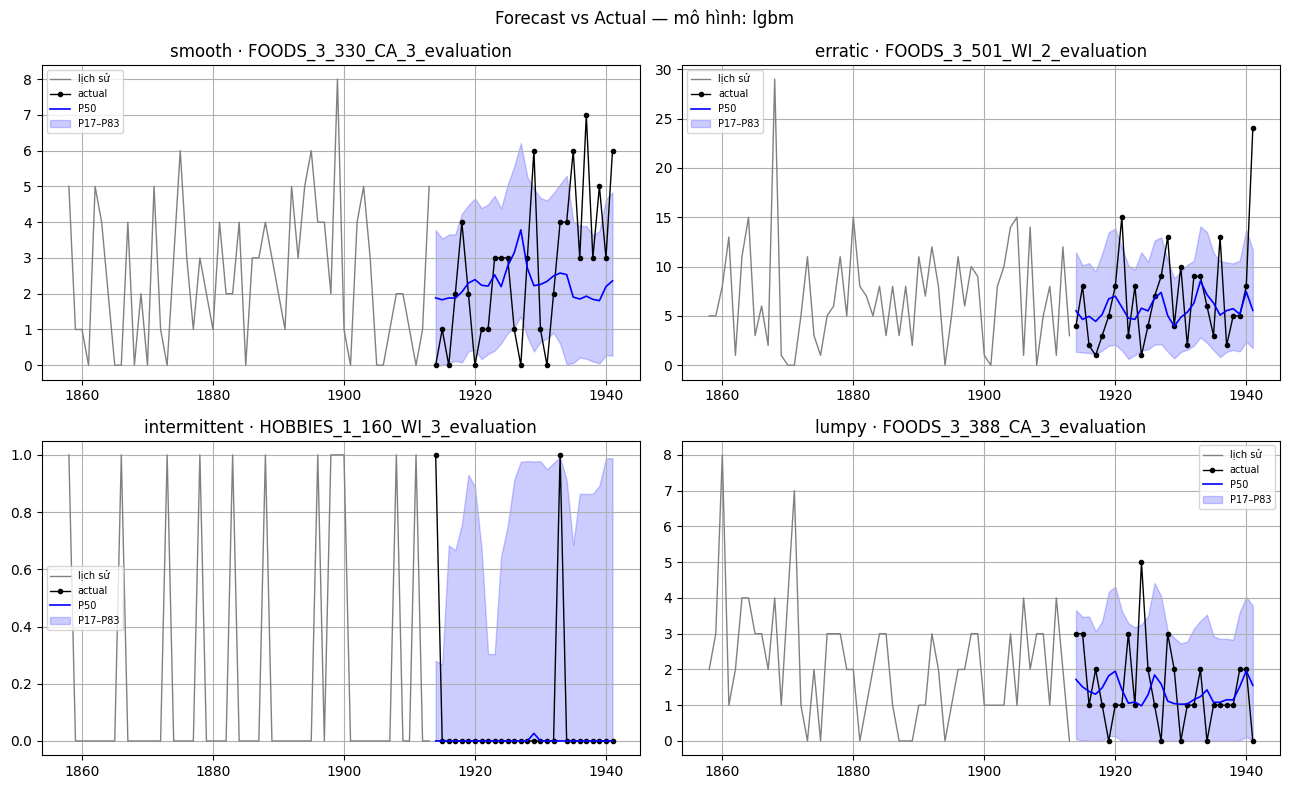

In [28]:
# --- 7.6 Biểu đồ forecast vs actual: 1 chuỗi đại diện mỗi nhóm -------------
prefer = [m for m in ["lgbm","chronos_bolt","sba","snaive","naive"] if m in all_fc][:1]
model_for_plot = prefer[0] if prefer else list(all_fc)[0]
fdf = all_fc[model_for_plot]
fig, axes = plt.subplots(2, 2, figsize=(13, 8)); axes = axes.ravel()
for ax, seg in zip(axes, SEG_ORDER):
    cand = actual_test[actual_test.segment == seg].groupby("series_id")["actual"].sum()
    cand = cand[cand > 0]
    if len(cand) == 0:
        ax.set_title(f"{seg}: (không có chuỗi bán trong test)"); continue
    sid = cand.index[len(cand)//2]
    hist = long[(long.series_id == sid) & (long.d_int > CONFIG["VAL_END"]-56)
                & (long.d_int <= CONFIG["VAL_END"])]
    act  = actual_test[actual_test.series_id == sid].sort_values("d_int")
    f    = fdf[fdf.series_id == sid]
    pv   = f.pivot_table(index="d_int", columns="quantile_level", values="value").sort_index()
    ax.plot(hist.d_int, hist.sales, color="gray", lw=1, label="lịch sử")
    ax.plot(act.d_int, act.actual, "k.-", lw=1, label="actual")
    ax.plot(pv.index, pv[0.5], "b-", lw=1.2, label="P50")
    if 0.165 in pv and 0.835 in pv:
        ax.fill_between(pv.index, pv[0.165], pv[0.835], color="b", alpha=0.2, label="P17–P83")
    ax.set_title(f"{seg} · {sid}"); ax.legend(fontsize=7)
fig.suptitle(f"Forecast vs Actual — mô hình: {model_for_plot}"); plt.tight_layout(); plt.show()

---
## §8 — Thực tế vs Plan (mục tiêu cốt lõi)

Tổng kết những chỗ **thực tế lệch kế hoạch** khi chạy thử, để chỉnh plan trước khi giao nhóm.

In [29]:
# --- 8.1 Tổng kết động (sinh từ log chạy thật) -----------------------------
print("="*70)
print("TỔNG KẾT: THỰC TẾ vs PLAN")
print("="*70)
print("\\n[1] PHẦN CỨNG")
print(f"    - GPU/CUDA khả dụng: {AVAILABLE.get('cuda')}  (plan giả định Colab T4 + fp16)")
print("\\n[2] CÀI ĐẶT PACKAGE")
for p, s in INSTALL_LOG.items():
    print(f"    - {p:22s}: {s}")
print("\\n[3] MÔ HÌNH CHẠY ĐƯỢC")
print(f"    - Có forecast: {list(all_fc.keys())}")
print(f"    - LightGBM: {'có' if lgbm_fc is not None else 'KHÔNG (thiếu lightgbm)'}")
print(f"    - statsforecast runtime: {sf_runtime}")
print("\\n[4] FOUNDATION MODELS")
for k in ["chronos_bolt","ttm"]:
    print(f"    - {k:14s}: {fm_log.get(k,'-')}  | runtime={fm_runtime.get(k,'-')}s")
print("\\n[5] QUY MÔ THỰC TẾ")
print(f"    - Mẫu: {len(sample_ids)} chuỗi ({CONFIG['SAMPLE_PER_SEGMENT']}/nhóm) × 1 cửa sổ test 28 ngày")
print(f"    - Nhóm demand: {sample_df.segment.value_counts().to_dict()}")
print("="*70)

TỔNG KẾT: THỰC TẾ vs PLAN
\n[1] PHẦN CỨNG
    - GPU/CUDA khả dụng: False  (plan giả định Colab T4 + fp16)
\n[2] CÀI ĐẶT PACKAGE
    - pyarrow               : ok (already installed)
    - lightgbm              : ok (already installed)
    - statsforecast         : ok (already installed)
    - utilsforecast         : ok (already installed)
    - chronos-forecasting   : ok (already installed)
    - transformers          : ok (already installed)
    - accelerate            : ok (already installed)
    - granite-tsfm          : ok (already installed)
\n[3] MÔ HÌNH CHẠY ĐƯỢC
    - Có forecast: ['lgbm', 'naive', 'snaive', 'croston', 'sba', 'tsb', 'chronos_bolt', 'ttm']
    - LightGBM: có
    - statsforecast runtime: {'statsforecast(3 models)': 1.5}
\n[4] FOUNDATION MODELS
    - chronos_bolt  : OK (amazon/chronos-bolt-base, ctx=512)  | runtime=28.7s
    - ttm           : OK (ibm-granite/granite-timeseries-ttm-r2, CL=512, PL=96)  | runtime=1.4s
\n[5] QUY MÔ THỰC TẾ
    - Mẫu: 800 chuỗi (200/nhó

### 8.2 Nhận xét & đề xuất chỉnh plan (điền/đọc sau khi chạy)

Những điểm **thường lệch** so với plan (kiểm chứng bằng output ở trên):

1. **Phần cứng CPU-only** — plan giả định Colab T4. FM chạy trên CPU: xem `fm_runtime` để ước lượng
   thời gian khi scale lên 1.000 chuỗi/nhóm (nhân tuyến tính theo số chuỗi).
2. **Cài đặt FM có rủi ro** — `granite-tsfm`/`uni2ts` đôi khi lệch version với `torch` mới; xem mục [2].
   Nếu TTM/Moirai fail ⇒ plan nên chốt version pin hoặc container.
3. **Point→quantile bằng NB** cho model cổ điển ảnh hưởng mạnh coverage — so `cov95` với 0.95 ở §7.2.
   Nếu coverage lệch, cân nhắc hiệu chỉnh dispersion hoặc dùng phân phối khác cho nhóm lumpy.
4. **Chronos-Bolt & quantile cực biên (0.005/0.995)** — model chỉ học tới ~[0.1,0.9]; đuôi bị ngoại suy.
   Cân nhắc ghi chú giới hạn này khi kết luận về hiệu chuẩn đuôi.
5. **Kết quả theo nhóm** — đối chiếu `decision` với kỳ vọng plan (cổ điển mạnh ở intermittent/lumpy;
   LightGBM mạnh ở smooth/erratic; FM cạnh tranh ở smooth/erratic). Ghi lại chỗ **trái kỳ vọng**.
6. **Rò rỉ pre-training FM** — Chronos/TTM có thể đã thấy M5; diễn giải zero-shot cần thận trọng.

> Ghi chú: đây là **pilot 200/nhóm, 1 cửa sổ** — dùng để kiểm luồng & phát hiện lỗi vận hành,
> **chưa phải kết quả cuối** để kết luận khoa học. Khi có GPU: tăng `SAMPLE_PER_SEGMENT`, thêm Moirai-2,
> bật few-shot, và rolling 2–3 cửa sổ.